# [추가 실험] Kkma 형태소 분석기 비교

과제 안내의 "KoNLPy에 있는 Mecab, kkma, Okt 등과 비교해보세요"에서 v2에 빠졌던 Kkma를 채운다.

**질문:** Kkma는 실제로 얼마나 느린가? 감정 분석 성능은 MeCab·Okt·SentencePiece와 비교해 어느 정도인가?

**조건은 v2와 같다:** NSMC 전체, 검증 10% 분리(`random_state=42`), MAX_LEN 60, BiLSTM(임베딩 128, 은닉 128), 10에폭 중 최고 검증 에폭으로 테스트 1회, 시드 5개. vocab은 학습 데이터 빈도순으로 자르고(0=pad, 1=unk), Okt와 같은 16000과 MeCab 최고 설정과 같은 8000 두 가지로 본다.

**Colab 사용법:** 런타임 유형은 GPU(A100) + 고용량 RAM으로 두고 **모두 실행**. Kkma 분석은 CPU 작업이라, CPU 코어 수만큼 Kkma를 따로 띄워 병렬로 돌린다. `1. 속도 측정` 셀에 예상 시간이 나온다.

## 설치 (konlpy, Kkma용 Java)

In [1]:
!pip install -q konlpy
!java -version 2>/dev/null || (apt-get -qq update > /dev/null && apt-get -qq install -y default-jdk-headless > /dev/null && echo "java installed")

[0.028s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.028s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate


## 데이터 (v2와 같은 분할)

In [2]:
import os, random, copy, time, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pad_sequence

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device, torch.cuda.get_device_name(0) if device == 'cuda' else '', '/ CPU 코어', os.cpu_count())

SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 10
MAX_LEN = 60
BATCH = 256

!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
!wget -q -nc https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt

def load(path):
    df = pd.read_table(path).dropna().drop_duplicates(subset=['document'])
    df['document'] = df['document'].str.replace('\n', ' ')
    return df[df['document'].str.strip() != ''].reset_index(drop=True)

train_all = load('ratings_train.txt')
test_df = load('ratings_test.txt')
val_df = train_all.groupby('label', group_keys=False).sample(frac=0.1, random_state=42)
train_df = train_all.drop(val_df.index)
texts = {'train': train_df['document'].tolist(), 'val': val_df['document'].tolist(), 'test': test_df['document'].tolist()}
labels = {'train': train_df['label'].values, 'val': val_df['label'].values, 'test': test_df['label'].values}
for k in texts:
    print(f'{k:5s} {len(texts[k]):7,d}개  긍정 비율 {labels[k].mean():.3f}')
N_TOTAL = sum(len(v) for v in texts.values())

cuda NVIDIA A100-SXM4-80GB / CPU 코어 12
train 131,564개  긍정 비율 0.498
val    14,618개  긍정 비율 0.498
test   49,157개  긍정 비율 0.503


## 1. 속도 측정

검증 리뷰 1,000개를 한 프로세스에서 Kkma로 분석해 시간을 재고, 전체(약 19.5만 개)로 환산한다. v2에서 잰 시간은 MeCab 13초, Okt 742초다.

In [3]:
from konlpy.tag import Kkma
kkma = Kkma()
kkma.morphs('워밍업 문장입니다.')

sample = texts['val'][:1000]
t0 = time.time()
sample_morphs = [kkma.morphs(t) for t in sample]
per_sent = (time.time() - t0) / len(sample)

est_single = per_sent * N_TOTAL
workers = max(1, (os.cpu_count() or 2) - 1)
print(f'1,000개 {per_sent * 1000:.1f}초 → 1개당 {per_sent * 1000:.1f}ms')
print(f'전체 {N_TOTAL:,}개 예상: 1프로세스 {est_single / 60:.0f}분 / {workers}프로세스 병렬 약 {est_single / workers / 60:.0f}분')
print(f'Okt(742초) 대비 약 {est_single / 742:.1f}배, MeCab(13초) 대비 약 {est_single / 13:.0f}배')
for t, m in list(zip(sample, sample_morphs))[:3]:
    print(t, '→', ' / '.join(m))

1,000개 23.7초 → 1개당 23.7ms
전체 195,339개 예상: 1프로세스 77분 / 11프로세스 병렬 약 7분
Okt(742초) 대비 약 6.2배, MeCab(13초) 대비 약 356배
설정이 복잡하고 캐릭터가 죽어 있어 마지막 전에 질린다 → 설정 / 이 / 복잡 / 하 / 고 / 캐릭터 / 가 / 죽 / 어 / 있 / 어 / 마지막 / 전 / 에 / 질리 / ㄴ다
줄거리 진짜 꽝... 슈퍼가 보는맛에 버텼다... → 줄거리 / 진짜 / 꽝 / ... / 슈퍼 / 가 / 보 / 는 / 맛 / 에 / 버티 / 었 / 다 / ...
영화가 끝나갈무렵 범이가 칼맞고 쓰러졋을때 수경이가 발로 찾을때... 난 그장면이 제일 임팩트 잇는것같다! → 영화 / 가 / 끝나가 / ㄹ / 무렵 / 범 / 이 / 가 / 아 / 칼 / 맞 / 고 / 쓰 / 러 / 졋 / 을 / 때 / 수경 / 이 / 가 / 아 / 발 / 로 / 찾 / 을 / 때 / ... / 나 / 는 / 그 / 장면 / 이 / 제일 / 임팩트 / 잇 / 는 / 것 / 같 / 다 / !


## 2. 전체 형태소 분석 (병렬)

프로세스마다 Kkma(와 JVM)를 따로 띄운다. 이미 JVM이 뜬 프로세스를 복제(fork)하면 멈출 수 있어서 `spawn` 방식으로 새로 띄운다. 분석에 실패한 문장은 공백 기준으로 대신 나누고 개수를 센다. 끝나면 결과를 `kkma_morphs.pkl`로 저장해, 런타임이 살아 있으면 다시 돌려도 분석을 건너뛴다.

In [4]:
%%writefile kkma_worker.py
from konlpy.tag import Kkma

_kkma = None

def init():
    global _kkma
    _kkma = Kkma()

def morphs_batch(batch):
    out, failed = [], 0
    for t in batch:
        try:
            out.append(_kkma.morphs(t))
        except Exception:
            out.append(t.split())
            failed += 1
    return out, failed

Writing kkma_worker.py


In [5]:
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
import kkma_worker

CACHE = 'kkma_morphs.pkl'
if os.path.exists(CACHE):
    MORPH = pickle.load(open(CACHE, 'rb'))
    print('저장된 분석 결과를 불러왔다:', {k: len(v) for k, v in MORPH.items()})
else:
    CHUNK = 500
    MORPH, failed_total = {}, 0
    t_all = time.time()
    with ProcessPoolExecutor(max_workers=workers, mp_context=mp.get_context('spawn'), initializer=kkma_worker.init) as ex:
        for k, v in texts.items():
            chunks = [v[i:i + CHUNK] for i in range(0, len(v), CHUNK)]
            out = []
            for j, (res, failed) in enumerate(ex.map(kkma_worker.morphs_batch, chunks), 1):
                out.extend(res)
                failed_total += failed
                if j % 20 == 0 or j == len(chunks):
                    print(f'{k:5s} {min(j * CHUNK, len(v)):7,d}/{len(v):,}  경과 {(time.time() - t_all) / 60:.1f}분', flush=True)
            MORPH[k] = out
    elapsed = time.time() - t_all
    print(f'Kkma 형태소 분석 {elapsed:.0f}초 ({elapsed / 60:.1f}분, {workers}프로세스), 실패해서 공백으로 나눈 문장 {failed_total}개')
    pickle.dump(MORPH, open(CACHE, 'wb'))
assert all(len(MORPH[k]) == len(texts[k]) for k in texts)

train  10,000/131,564  경과 3.1분
train  20,000/131,564  경과 3.1분
train  30,000/131,564  경과 3.1분
train  40,000/131,564  경과 14.7분
train  50,000/131,564  경과 14.7분
train  60,000/131,564  경과 14.7분
train  70,000/131,564  경과 14.7분
train  80,000/131,564  경과 14.7분
train  90,000/131,564  경과 14.7분
train 100,000/131,564  경과 14.7분
train 110,000/131,564  경과 14.7분
train 120,000/131,564  경과 14.7분
train 130,000/131,564  경과 14.7분
train 131,564/131,564  경과 14.7분
val    10,000/14,618  경과 21.0분
val    14,618/14,618  경과 21.0분
test   10,000/49,157  경과 21.7분
test   20,000/49,157  경과 22.4분
test   30,000/49,157  경과 24.3분
test   40,000/49,157  경과 35.8분
test   49,157/49,157  경과 35.8분
Kkma 형태소 분석 2150초 (35.8분, 11프로세스), 실패해서 공백으로 나눈 문장 5개


## 3. 단어 사전과 토큰 통계

In [6]:
def to_tensor(id_lists, max_len):
    seqs = [torch.tensor(ids[:max_len] or [1], dtype=torch.long) for ids in id_lists]
    return pad_sequence(seqs, batch_first=True, padding_value=0)

cnt = Counter(w for ts in MORPH['train'] for w in ts)
print(f'Kkma 학습 데이터 고유 형태소 {len(cnt):,}개')

TOK, rows = {}, []
for vs in [8000, 16000]:
    word_index = {w: i + 2 for i, (w, _) in enumerate(cnt.most_common(vs - 2))}
    ids = {k: [[word_index.get(w, 1) for w in ts] for ts in v] for k, v in MORPH.items()}
    TOK[f'Kkma-{vs}'] = dict(X={k: to_tensor(v, MAX_LEN) for k, v in ids.items()}, vocab_size=vs)
    lens = np.array([len(x) for x in ids['train']])
    va_total = sum(len(x) for x in ids['val'])
    rows.append(dict(tokenizer=f'Kkma-{vs}', avg_tokens=lens.mean(), p95_tokens=np.percentile(lens, 95),
                     cut_ratio=(lens > MAX_LEN).mean(), unk_val=sum(x.count(1) for x in ids['val']) / va_total))
display(pd.DataFrame(rows).set_index('tokenizer').round(4))
print('v2 참고: MeCab avg_tokens 18.72 / cut 0.0397 / unk_val 0.0463(8000)·0.0258(16000), Okt-16000 14.67 / 0.0047 / 0.0805')

for t in texts['val'][:3]:
    print(t, '→', ' / '.join(MORPH['val'][texts['val'].index(t)]))

Kkma 학습 데이터 고유 형태소 40,895개


,avg_tokens,p95_tokens,cut_ratio,unk_val
tokenizer,,,,
Kkma-8000,20.2516,61.0,0.0501,0.0320
Kkma-16000,20.2516,61.0,0.0501,0.0156


v2 참고: MeCab avg_tokens 18.72 / cut 0.0397 / unk_val 0.0463(8000)·0.0258(16000), Okt-16000 14.67 / 0.0047 / 0.0805
설정이 복잡하고 캐릭터가 죽어 있어 마지막 전에 질린다 → 설정 / 이 / 복잡 / 하 / 고 / 캐릭터 / 가 / 죽 / 어 / 있 / 어 / 마지막 / 전 / 에 / 질리 / ㄴ다
줄거리 진짜 꽝... 슈퍼가 보는맛에 버텼다... → 줄거리 / 진짜 / 꽝 / ... / 슈퍼 / 가 / 보 / 는 / 맛 / 에 / 버티 / 었 / 다 / ...
영화가 끝나갈무렵 범이가 칼맞고 쓰러졋을때 수경이가 발로 찾을때... 난 그장면이 제일 임팩트 잇는것같다! → 영화 / 가 / 끝나가 / ㄹ / 무렵 / 범 / 이 / 가 / 아 / 칼 / 맞 / 고 / 쓰 / 러 / 졋 / 을 / 때 / 수경 / 이 / 가 / 아 / 발 / 로 / 찾 / 을 / 때 / ... / 나 / 는 / 그 / 장면 / 이 / 제일 / 임팩트 / 잇 / 는 / 것 / 같 / 다 / !


## 4. 학습 (v2와 같은 모델·학습 방법)

In [7]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        self.lstm = nn.LSTM(emb_dim, hidden, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden * 2, 1)

    def forward(self, x):
        out, _ = self.lstm(self.emb(x))
        mask = (x != 0).unsqueeze(-1).float()
        pooled = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(pooled).squeeze(-1)

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

@torch.no_grad()
def predict(model, X, bs=4096):
    model.eval()
    return torch.cat([(model(X[i:i + bs]) > 0).long().cpu() for i in range(0, len(X), bs)]).numpy()

def run(X, y, vocab_size, seed, epochs=EPOCHS, bs=BATCH):
    set_seed(seed)
    Xtr, Xva, Xte = X['train'].to(device), X['val'].to(device), X['test'].to(device)
    ytr = torch.tensor(y['train'], dtype=torch.float, device=device)
    model = LSTMClassifier(vocab_size).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)
    loss_fn = nn.BCEWithLogitsLoss()
    g = torch.Generator().manual_seed(seed)
    hist, best_acc, best_state, best_ep = [], -1, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr), generator=g).to(device)
        total = 0.0
        for i in range(0, len(perm), bs):
            idx = perm[i:i + bs]
            opt.zero_grad()
            loss = loss_fn(model(Xtr[idx]), ytr[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        va_acc = (predict(model, Xva) == y['val']).mean()
        hist.append(dict(epoch=ep, train_loss=total / len(Xtr), val_acc=va_acc))
        if va_acc > best_acc:
            best_acc, best_state, best_ep = va_acc, copy.deepcopy(model.state_dict()), ep
    model.load_state_dict(best_state)
    te_pred = predict(model, Xte)
    return dict(seed=seed, best_ep=best_ep, val_acc=best_acc, test_acc=(te_pred == y['test']).mean(), hist=hist)

RESULTS = []
for name, t in TOK.items():
    for seed in SEEDS:
        t0 = time.time()
        r = run(t['X'], labels, t['vocab_size'], seed)
        r['tokenizer'] = name
        RESULTS.append(r)
        print(f"{name:10s} seed {seed}  best_ep {r['best_ep']:2d}  val {r['val_acc']:.4f}  test {r['test_acc']:.4f}  ({time.time() - t0:.0f}s)")
json.dump(RESULTS, open('results_kkma.json', 'w'), default=float)

Kkma-8000  seed 0  best_ep  4  val 0.8669  test 0.8622  (31s)
Kkma-8000  seed 1  best_ep  4  val 0.8620  test 0.8616  (19s)
Kkma-8000  seed 2  best_ep  7  val 0.8644  test 0.8578  (19s)
Kkma-8000  seed 3  best_ep  4  val 0.8642  test 0.8625  (19s)
Kkma-8000  seed 4  best_ep  6  val 0.8622  test 0.8596  (19s)
Kkma-16000 seed 0  best_ep  4  val 0.8669  test 0.8627  (19s)
Kkma-16000 seed 1  best_ep  4  val 0.8637  test 0.8613  (19s)
Kkma-16000 seed 2  best_ep  5  val 0.8620  test 0.8609  (19s)
Kkma-16000 seed 3  best_ep  5  val 0.8642  test 0.8625  (19s)
Kkma-16000 seed 4  best_ep  5  val 0.8626  test 0.8607  (19s)


## 5. v2 결과와 비교 (시드 5개 평균 ± 표준편차)

,val_mean,val_std,test_mean,test_std,best_ep,출처
tokenizer,,,,,,
MeCab-8000,0.8647,0.0017,0.8620,0.0022,4.2,v2
MeCab-16000,0.8640,0.0024,0.8625,0.0006,4.8,v2
Kkma-8000,0.8639,0.0020,0.8607,0.0020,5.0,이번 실행
Kkma-16000,0.8639,0.0019,0.8616,0.0009,4.6,이번 실행
Okt-16000,0.8532,0.0012,0.8498,0.0017,3.8,v2
SPM-unigram-16000,0.8515,0.0006,0.8469,0.0013,3.8,v2


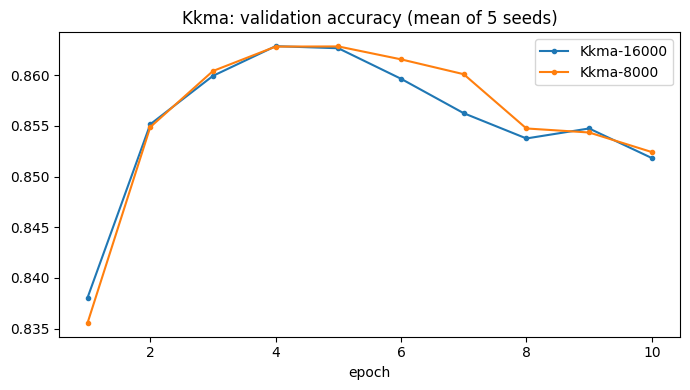

In [8]:
df = pd.DataFrame([{k: v for k, v in r.items() if k != 'hist'} for r in RESULTS])
kkma_summary = df.groupby('tokenizer').agg(val_mean=('val_acc', 'mean'), val_std=('val_acc', 'std'),
                                           test_mean=('test_acc', 'mean'), test_std=('test_acc', 'std'),
                                           best_ep=('best_ep', 'mean'))
v2 = pd.DataFrame([
    ('MeCab-8000',        0.8647, 0.0017, 0.8620, 0.0022, 4.2),
    ('MeCab-16000',       0.8640, 0.0024, 0.8625, 0.0006, 4.8),
    ('Okt-16000',         0.8532, 0.0012, 0.8498, 0.0017, 3.8),
    ('SPM-unigram-16000', 0.8515, 0.0006, 0.8469, 0.0013, 3.8),
], columns=['tokenizer', 'val_mean', 'val_std', 'test_mean', 'test_std', 'best_ep']).set_index('tokenizer')
compare = pd.concat([kkma_summary, v2]).sort_values('val_mean', ascending=False)
compare['출처'] = ['이번 실행' if i.startswith('Kkma') else 'v2' for i in compare.index]
display(compare.round(4))

hist = pd.DataFrame([dict(h, tokenizer=r['tokenizer'], seed=r['seed']) for r in RESULTS for h in r['hist']])
curve = hist.groupby(['tokenizer', 'epoch'])['val_acc'].mean().reset_index()
plt.figure(figsize=(7, 4))
for name, g in curve.groupby('tokenizer'):
    plt.plot(g['epoch'], g['val_acc'], marker='o', ms=3, label=name)
plt.title('Kkma: validation accuracy (mean of 5 seeds)')
plt.xlabel('epoch')
plt.legend()
plt.tight_layout()
plt.show()

## 결과 해석

| 토크나이저 | 검증 | 테스트 | 최고 에폭 | 문장당 토큰 | `<unk>`(검증) | 형태소 분석 시간 |
|---|---|---|---|---|---|---|
| MeCab-8000 (v2) | **0.8647 ± 0.0017** | 0.8620 ± 0.0022 | 4.2 | 18.7 | 4.6% | 13초 |
| MeCab-16000 (v2) | 0.8640 ± 0.0024 | **0.8625 ± 0.0006** | 4.8 | 18.7 | 2.6% | 13초 |
| **Kkma-8000** | 0.8639 ± 0.0020 | 0.8607 ± 0.0020 | 5.0 | 20.3 | 3.2% | 2,150초 (11프로세스) |
| **Kkma-16000** | 0.8639 ± 0.0019 | 0.8616 ± 0.0009 | 4.6 | 20.3 | 1.6% | 〃 |
| Okt-16000 (v2) | 0.8532 ± 0.0012 | 0.8498 ± 0.0017 | 3.8 | 14.7 | 8.1% | 742초 |
| SPM-unigram-16000 (v2) | 0.8515 ± 0.0006 | 0.8469 ± 0.0013 | 3.8 | 15.4 | 0.1% | SPM 6개 학습·인코딩 합계 96초 |

- **정확도는 MeCab과 거의 같다.** 검증 0.8639로 MeCab-8000(0.8647)보다 0.08%p 낮을 뿐이다. 이 차이는 시드 표준편차(0.17~0.24%p)보다 작다. Okt(0.8532)나 SentencePiece(0.8515)보다는 1%p 넘게 높다.
- **대신 매우 느리다.** 1,000개로 재면 1개당 23.7ms로, 한 프로세스로는 전체 약 77분이다(MeCab의 약 356배, Okt의 약 6.2배). 11프로세스 병렬로 돌렸는데도 실제로는 35.8분이 걸렸다. 속도 측정으로 낸 예상(7분)보다 5배 느렸다. 진행 기록을 보면 중간에 10분 넘게 멈춘 구간이 있었는데, 특정 문장에서 오래 걸린 것인지는 확인하지 못했다. 분석에 실패한 문장은 5개였다(공백으로 대신 나눔).
- **가장 잘게 나눈다.** 문장당 20.3토큰으로 MeCab(18.7)보다 많다. `버텼다`를 `버티 / 었 / 다`로, `질린다`를 `질리 / ㄴ다`로 나누는 것처럼 활용된 말을 기본형과 어미로 되돌린다.
- **잘게 나누는 것보다 "어디서" 나누는지가 중요해 보인다.** 어간과 어미를 떼어 내는 MeCab·Kkma는 0.864 근처였다. 반면 `복잡하고`, `버텼다`처럼 붙여 두는 Okt와, `▁복잡 / 하고`처럼 나누는 SentencePiece(unigram-8000 예시)는 0.85 근처였다. 그런데 SPM-unigram-4000도 문장당 20.2토큰으로 Kkma만큼 잘게 나누지만 검증 0.8514에 그쳤다. 토큰 수가 아니라 형태소 경계에서 나누는지가 차이를 만든 것으로 보인다(모델 하나로 본 상관관계라 단정하지는 않는다).